In [1]:
#Mount Drive
# Import the Colab helper that connects Google Drive to this notebook
from google.colab import drive
# Mount Drive at /content/drive; force_remount=True asks for permission again so a fresh login is used
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
#Unzip the dataset
# os and zipfile are imported but not used below; Path is used to handle file paths
import os, zipfile
from pathlib import Path

# Where the dataset zip should be in Drive
ZIP_PATH = Path("/content/drive/MyDrive/fresh_vs_rotten_dataset.zip")
# Where the dataset will be extracted (Colab local storage, which is faster than Drive)
DEST_DIR = Path("/content/dataset")

# If the zip is not directly in My Drive, search all subfolders for it
if not ZIP_PATH.exists():
    # rglob searches recursively; list() turns the matches into a list
    found = list(Path("/content/drive/MyDrive").rglob("fresh_vs_rotten_dataset.zip"))
    # Use the first match if anything was found
    if found:
        ZIP_PATH = found[0]

# Unzip only if the zip exists and we have not extracted it already
if ZIP_PATH.exists() and not DEST_DIR.exists():
    print("Unzipping...")
    # Shell command: -q = quiet, -d = destination folder; {..} inserts the Python variables
    !unzip -q "{ZIP_PATH}" -d "{DEST_DIR}"
    print("Done")
# The dataset folder already exists from an earlier run, so skip unzipping
elif DEST_DIR.exists():
    print("Already extracted")
# The zip was not found anywhere
else:
    print("Zip not found in Drive")

Unzipping...
Done


In [3]:
#Imports and find the folders
# Standard libraries: files, timing, JSON, regular expressions, copying objects
import os, time, json, re, copy
from pathlib import Path
# Numbers, plotting and the heatmap style plots
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# PyTorch and its neural network module
import torch, torch.nn as nn
# torchvision: datasets, image transforms and pretrained models
from torchvision import datasets, transforms, models
# DataLoader feeds data to the model in batches
from torch.utils.data import DataLoader
# Metrics used in the evaluation
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# Use the GPU if there is one, otherwise the CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)    # must say cuda

# Returns the subfolder of root whose name STARTS with one of the given words
# (this is why "train (70%)" is found with the word "train")
def get_split(root, prefixes):
    # Go through everything inside root
    for d in root.iterdir():
        # Match only folders whose lower-cased name starts with a given prefix
        if d.is_dir() and d.name.lower().startswith(tuple(prefixes)):
            return d
    # Nothing matched
    return None

# Finds the folder that contains both a train folder and a test folder
def find_dataset_root(base):
    # Check the base folder itself and every folder below it
    for p in [base] + list(base.rglob("*")):
        # Skip the junk folder that macOS zips create, and skip files
        if "__MACOSX" in str(p) or not p.is_dir():
            continue
        # This is the root if it holds both train and test folders
        if get_split(p, ["train"]) and get_split(p, ["test"]):
            return p
    return None

# Locate the dataset inside the unzipped folder
ROOT = find_dataset_root(Path("/content/dataset"))
print("Dataset root:", ROOT)
# Stop with a clear message if the dataset was not found
assert ROOT is not None, "Dataset not found"

# Paths of the three splits
TRAIN_DIR = get_split(ROOT, ["train"])
VAL_DIR   = get_split(ROOT, ["val"])
TEST_DIR  = get_split(ROOT, ["test"])
print("Train:", TRAIN_DIR.name, "| Val:", VAL_DIR.name, "| Test:", TEST_DIR.name)

Using device: cuda
Dataset root: /content/dataset/fresh_vs_rotten_dataset
Train: train (70%) | Val: val (15%) | Test: test (15%)


In [4]:
# collections gives Counter and defaultdict
import re, collections

# Pattern for augmentation prefixes at the start of a file name (flip_, rotate_, ...)
AUG_PREFIX = r"^((vertical_flip|horizontal_flip|flip|rotate\w*|rotation\w*|brightness\w*|bright\w*|crop\w*|zoom\w*|shear\w*|noise\w*|blur\w*|contrast\w*)[_\- ]+)+"

# Splits a file name into (augmentation prefix, name of the ORIGINAL photo)
def split_name(fname):
    # File name without the extension
    stem = Path(fname).stem
    # Screenshot names: everything from "Screen Shot" onward is the original photo's name
    m = re.search(r"(Screen\s?Shot.*)", stem, re.I)
    # Use that, otherwise remove the augmentation prefix from the name
    key = m.group(1) if m else re.sub(AUG_PREFIX, "", stem, flags=re.I)
    # The prefix is whatever came before the key; the key is lower-cased for comparison
    return stem[:len(stem) - len(key)], key.lower()

# Count how many files have each augmentation prefix
prefixes = collections.Counter()
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    for f in split_dir.rglob("*"):
        if f.is_file():
            # Files with no prefix are counted as "(no prefix)"
            prefixes[split_name(f.name)[0] or "(no prefix)"] += 1
print("Prefix counts:", prefixes.most_common())

# For each (class, original photo), remember which splits it appears in
where = collections.defaultdict(set)
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    for f in split_dir.rglob("*"):
        if f.is_file():
            # f.parent.name is the class folder; the first 3 letters of the split name label the split
            where[(f.parent.name, split_name(f.name)[1])].add(split_dir.name[:3])
# An original photo present in more than one split is leakage
leaky = sum(len(s) > 1 for s in where.values())
print(f"Original photos: {len(where)} | present in more than one split: {leaky}")


Prefix counts: [('(no prefix)', 9165), ('rotated_by_15_', 1240), ('rotated_by_60_', 1224), ('rotated_by_30_', 1217), ('rotated_by_45_', 1208), ('rotated_by_75_', 1198), ('saltandpepper_', 1157), ('translation_', 1047), ('vertical_flip_', 1033)]
Original photos: 8933 | present in more than one split: 1395


In [5]:
# random shuffles the photos; shutil copies and deletes folders
import random, shutil

# The new, leak-free dataset will be built here
NEW_ROOT = Path("/content/dataset_clean")
# Delete an old copy so we always start clean
if NEW_ROOT.exists():
    shutil.rmtree(NEW_ROOT)
# Fixed seed so the shuffle (and so the split) is the same every run
random.seed(42)
# Image file types to keep
exts = {".jpg", ".jpeg", ".png"}
# Names of the 8 class folders, sorted
all_classes = sorted(d.name for d in TRAIN_DIR.iterdir() if d.is_dir())

# Process one class at a time
for cls in all_classes:
    # groups: original photo name -> list of all its files (augmented copies)
    groups = collections.defaultdict(list)
    # Collect the files of this class from all three original splits
    for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
        for f in (split_dir / cls).glob("*"):
            if f.suffix.lower() in exts:
                groups[split_name(f.name)[1]].append(f)

    # List the original photos, shuffle them
    keys = sorted(groups)
    random.shuffle(keys)
    n = len(keys)
    # 70% of the originals for training, 15% for validation, the rest (15%) for test
    n_tr, n_va = int(0.70 * n), int(0.15 * n)
    parts = {"train": keys[:n_tr], "val": keys[n_tr:n_tr + n_va], "test": keys[n_tr + n_va:]}

    # Copy the files into the new folders
    for split, ks in parts.items():
        out = NEW_ROOT / split / cls
        # Create the folder (and parents) if it does not exist
        out.mkdir(parents=True, exist_ok=True)
        for k in ks:
            # All files (original + copies) of this photo
            files = groups[k]
            # For validation and test keep only ONE file per original: the one with the shortest prefix (least augmented)
            if split != "train":
                files = sorted(files, key=lambda f: len(split_name(f.name)[0]))[:1]
            # Copy the chosen files
            for f in files:
                shutil.copy(f, out / f.name)

# From now on the notebook uses the clean dataset
TRAIN_DIR, VAL_DIR, TEST_DIR = NEW_ROOT / "train", NEW_ROOT / "val", NEW_ROOT / "test"
# Print the number of images per class in each split
for d in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    print(d.name, {c: len(list((d / c).glob("*"))) for c in all_classes})

train {'fresh_apple': 1661, 'fresh_banana': 1422, 'fresh_mango': 1262, 'fresh_orange': 1477, 'rotten_apple': 2079, 'rotten_banana': 1932, 'rotten_mango': 1573, 'rotten_orange': 1530}
val {'fresh_apple': 146, 'fresh_banana': 152, 'fresh_mango': 239, 'fresh_orange': 76, 'rotten_apple': 136, 'rotten_banana': 131, 'rotten_mango': 334, 'rotten_orange': 121}
test {'fresh_apple': 147, 'fresh_banana': 153, 'fresh_mango': 241, 'fresh_orange': 78, 'rotten_apple': 137, 'rotten_banana': 133, 'rotten_mango': 336, 'rotten_orange': 123}


In [6]:
# Folder in Drive where we keep our own photos, already split into train, val and test
MY_ROOT = Path("/content/drive/MyDrive/fresh_vs_rotten_fruit/fresh_vs_rotten_my_dataset")

# Go through each split of our own photos
for split in ["train", "val", "test"]:
    # Find the matching folder, e.g. "train (70%)"
    src_split = get_split(MY_ROOT, [split])
    # Skip this split if its folder is missing
    if src_split is None:
        print("Split folder not found:", split)
        continue
    for cls in all_classes:
        # Folder of this class inside our own split
        src = src_split / cls
        # Skip classes we have no photos for
        if not src.is_dir():
            continue
        # Matching folder inside the clean dataset
        out = NEW_ROOT / split / cls
        out.mkdir(parents=True, exist_ok=True)
        # Our photos of this class
        files = [f for f in src.glob("*") if f.suffix.lower() in exts]
        # Training photos are copied 5 times (augmentation makes each copy different); val and test once
        copies = 5 if split == "train" else 1
        for f in files:
            for c in range(copies):
                # my0_, my1_ ... in the file name keep the copies apart and mark them as our own photos
                shutil.copy(f, out / f"my{c}_{f.name}")
        print(f"{split:5s} {cls:15s} my photos: {len(files)}")

train fresh_apple     my photos: 17
train fresh_banana    my photos: 17
train fresh_mango     my photos: 17
train fresh_orange    my photos: 17
train rotten_apple    my photos: 17
train rotten_banana   my photos: 17
train rotten_mango    my photos: 17
train rotten_orange   my photos: 19
val   fresh_apple     my photos: 4
val   fresh_banana    my photos: 4
val   fresh_mango     my photos: 4
val   fresh_orange    my photos: 4
val   rotten_apple    my photos: 4
val   rotten_banana   my photos: 4
val   rotten_mango    my photos: 4
val   rotten_orange   my photos: 5
test  fresh_apple     my photos: 4
test  fresh_banana    my photos: 4
test  fresh_mango     my photos: 4
test  fresh_orange    my photos: 4
test  rotten_apple    my photos: 4
test  rotten_banana   my photos: 4
test  rotten_mango    my photos: 4
test  rotten_orange   my photos: 4


In [7]:
#Augmentation, labels, loaders
# Mean and standard deviation of ImageNet, used to normalise the images
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Training transforms: random changes so the model sees more variety (augmentation)
train_tf = transforms.Compose([
    # Random crop (30% to 100% of the image) resized to 224 x 224
    transforms.RandomResizedCrop(224, scale=(0.3, 1.0)),
    # Rotate randomly up to 30 degrees
    transforms.RandomRotation(30),
    # Flip left-right half of the time
    transforms.RandomHorizontalFlip(),
    # Random changes in brightness, contrast, saturation and hue
    transforms.ColorJitter(brightness=0.5, contrast=0.4, saturation=0.4, hue=0.03),
    # Slight random perspective tilt, applied to 30% of the images
    transforms.RandomPerspective(0.2, p=0.3),
    # Blur 30% of the images
    transforms.RandomApply([transforms.GaussianBlur(5)], p=0.3),
    # Convert the image to a tensor (numbers from 0 to 1)
    transforms.ToTensor(),
    # Normalise with the ImageNet mean and std
    transforms.Normalize(mean, std),
    # Hide a random patch in 30% of the images
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.15)),
])
# Validation/test transforms: no randomness, only resize and normalise
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Reads freshness from a class name: "rotten" if it contains rot, defect, bad or spoil
def get_freshness(name):
    name = name.lower()
    return "rotten" if any(w in name for w in ["rot", "defect", "bad", "spoil"]) else "fresh"

# Reads the fruit from a class name by removing the freshness word ("rotten_apple" -> "apple")
def get_fruit(name):
    # Replace the freshness words with a space
    name = re.sub(r"(fresh|rotten|defective|defect|bad|spoiled)", " ", name.lower())
    # Turn underscores, dashes and extra spaces into single spaces and trim
    return re.sub(r"[_\-\s]+", " ", name).strip()

# The 8 class names, found from the folder names (sorted alphabetically)
class_names = datasets.ImageFolder(TRAIN_DIR).classes
# The unique fruit names, sorted: apple, banana, mango, orange
fruit_list = sorted({get_fruit(c) for c in class_names})
# The two freshness labels (index 0 = fresh, 1 = rotten)
fresh_list = ["fresh", "rotten"]
print("Fruits:", fruit_list)

# Dataset that gives (image, fruit label, freshness label) for every image
class FruitData(torch.utils.data.Dataset):
    def __init__(self, folder, tf):
        # ImageFolder reads the images and gives each class folder a number
        self.base = datasets.ImageFolder(folder, transform=tf)
        # For each class number, its fruit number (0-3)
        self.fruit_of = [fruit_list.index(get_fruit(c)) for c in self.base.classes]
        # For each class number, its freshness number (0 = fresh, 1 = rotten)
        self.fresh_of = [fresh_list.index(get_freshness(c)) for c in self.base.classes]
    # Number of images
    def __len__(self):
        return len(self.base)
    # Returns one sample: the image plus both labels
    def __getitem__(self, i):
        img, y = self.base[i]
        return img, self.fruit_of[y], self.fresh_of[y]

# One dataset per split: augmentation only for training
train_data = FruitData(TRAIN_DIR, train_tf)
val_data   = FruitData(VAL_DIR,   eval_tf)
test_data  = FruitData(TEST_DIR,  eval_tf)

# Loaders give batches of 32 images; training data is shuffled each epoch, the others are not
train_loader = DataLoader(train_data, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_data,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_data,  batch_size=32, shuffle=False, num_workers=2)
print("Train / val / test images:", len(train_data), len(val_data), len(test_data))

Fruits: ['apple', 'banana', 'mango', 'orange']
Train / val / test images: 13626 1368 1380


In [8]:
#model
# The network: one shared backbone and two output heads
class FruitNet(nn.Module):
    def __init__(self, n_fruit, n_fresh, pretrained=True):
        super().__init__()
        # Load ImageNet weights if pretrained=True, otherwise start without them
        weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
        # Keep only the convolutional part (features) of MobileNetV2
        self.features = models.mobilenet_v2(weights=weights).features
        # Average each feature map to one number, giving 1280 values
        self.pool = nn.AdaptiveAvgPool2d(1)
        # Randomly switch off 30% of the values while training to reduce overfitting
        self.drop = nn.Dropout(0.3)
        # Head 1: which fruit (4 outputs)
        self.fruit_head = nn.Linear(1280, n_fruit)
        # Head 2: fresh or rotten (2 outputs)
        self.fresh_head = nn.Linear(1280, n_fresh)

    # What happens to an input batch x
    def forward(self, x):
        # features -> pool -> flatten to (batch, 1280) -> dropout
        x = self.drop(self.pool(self.features(x)).flatten(1))
        # Return the raw scores (logits) of both heads
        return self.fruit_head(x), self.fresh_head(x)

# Create the model (4 fruits, 2 freshness classes) and move it to the GPU/CPU
model = FruitNet(len(fruit_list), 2).to(device)

# Freeze the pretrained backbone so it is not updated in Phase 1
for p in model.features.parameters():
    p.requires_grad = False

# Loss function; label_smoothing=0.1 softens the targets so the model is not over-sure
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
print("Model ready")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 130MB/s]


Model ready


In [9]:
#training model
# Stores the numbers of every epoch so they can be plotted later
history = {"train_loss": [], "val_loss": [], "val_fruit_acc": [], "val_fresh_acc": []}
# Remember the best score and the weights that gave it
best_score, best_weights = 0.0, copy.deepcopy(model.state_dict())

# Runs one full pass over a loader; trains if train=True, otherwise only evaluates
def run_epoch(loader, train=False, optimizer=None, frozen=None):
    # Training mode (dropout on) or evaluation mode (dropout off)
    model.train() if train else model.eval()
    # Keep the frozen layers in eval mode so their BatchNorm statistics do not change
    if train and frozen is not None:
        frozen.eval()
    # Running totals: loss, correct fruit predictions, correct freshness predictions, image count
    total_loss = fruit_ok = fresh_ok = n = 0
    # Compute gradients only when training
    with torch.set_grad_enabled(train):
        for images, fruit, fresh in loader:
            # Move the batch to the GPU/CPU
            images, fruit, fresh = images.to(device), fruit.to(device), fresh.to(device)
            # Forward pass: scores of both heads
            out_fruit, out_fresh = model(images)
            # Total loss is the sum of the two head losses
            loss = criterion(out_fruit, fruit) + criterion(out_fresh, fresh)
            if train:
                # Clear old gradients
                optimizer.zero_grad()
                # Backward pass: compute the gradients
                loss.backward()
                # Update the weights
                optimizer.step()
            # Add this batch's loss (multiplied by batch size to get a sum)
            total_loss += loss.item() * images.size(0)
            # Count correct predictions: argmax gives the class with the highest score
            fruit_ok += (out_fruit.argmax(1) == fruit).sum().item()
            fresh_ok += (out_fresh.argmax(1) == fresh).sum().item()
            n += images.size(0)
    # Average loss and the two accuracies
    return total_loss / n, fruit_ok / n, fresh_ok / n

# Trains for a number of epochs and keeps the best model
def train_model(epochs, optimizer, frozen):
    # Allow changing the global variables defined above
    global best_score, best_weights
    for ep in range(epochs):
        # One training epoch, then one validation epoch
        tr_loss, _, _ = run_epoch(train_loader, True, optimizer, frozen)
        va_loss, va_fruit, va_fresh = run_epoch(val_loader)
        # Save this epoch's numbers
        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["val_fruit_acc"].append(va_fruit); history["val_fresh_acc"].append(va_fresh)
        # If the mean of the two validation accuracies is the best so far, keep these weights
        if (va_fruit + va_fresh) / 2 > best_score:
            best_score = (va_fruit + va_fresh) / 2
            best_weights = copy.deepcopy(model.state_dict())
        # Print the epoch summary
        print(f"Epoch {ep+1}/{epochs} | train loss {tr_loss:.3f} | val loss {va_loss:.3f} "
              f"| val fruit acc {va_fruit:.3f} | val fresh acc {va_fresh:.3f}")

# Phase 1: only the two new heads are trained (the backbone is frozen)
print("Phase 1: training the heads")
# Parameters of both heads
heads = list(model.fruit_head.parameters()) + list(model.fresh_head.parameters())
# Adam optimiser with learning rate 0.001, for 5 epochs
train_model(5, torch.optim.Adam(heads, lr=1e-3, weight_decay=1e-4), frozen=model.features)

# Phase 2: fine-tune the last 6 blocks of the backbone with a smaller learning rate
print("\nPhase 2: fine-tuning")
# Unfreeze the last 6 blocks
for p in model.features[-6:].parameters():
    p.requires_grad = True
# New optimiser over all trainable parameters, learning rate 0.0001
opt2 = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),
                        lr=1e-4, weight_decay=1e-4)
# Train for 8 epochs; the first blocks stay frozen (and in eval mode)
train_model(8, opt2, frozen=model.features[:-6])

# Load the best weights found during training back into the model
model.load_state_dict(best_weights)
print("\nBest average validation accuracy:", round(best_score, 4))


Phase 1: training the heads
Epoch 1/5 | train loss 1.025 | val loss 0.901 | val fruit acc 0.907 | val fresh acc 0.927
Epoch 2/5 | train loss 0.889 | val loss 0.849 | val fruit acc 0.927 | val fresh acc 0.933
Epoch 3/5 | train loss 0.866 | val loss 0.823 | val fruit acc 0.940 | val fresh acc 0.936
Epoch 4/5 | train loss 0.864 | val loss 0.810 | val fruit acc 0.945 | val fresh acc 0.946
Epoch 5/5 | train loss 0.861 | val loss 0.817 | val fruit acc 0.948 | val fresh acc 0.943

Phase 2: fine-tuning
Epoch 1/8 | train loss 0.892 | val loss 0.708 | val fruit acc 0.976 | val fresh acc 0.974
Epoch 2/8 | train loss 0.769 | val loss 0.678 | val fruit acc 0.982 | val fresh acc 0.977
Epoch 3/8 | train loss 0.724 | val loss 0.652 | val fruit acc 0.988 | val fresh acc 0.983
Epoch 4/8 | train loss 0.691 | val loss 0.638 | val fruit acc 0.988 | val fresh acc 0.988
Epoch 5/8 | train loss 0.681 | val loss 0.630 | val fruit acc 0.992 | val fresh acc 0.986
Epoch 6/8 | train loss 0.664 | val loss 0.618 | va

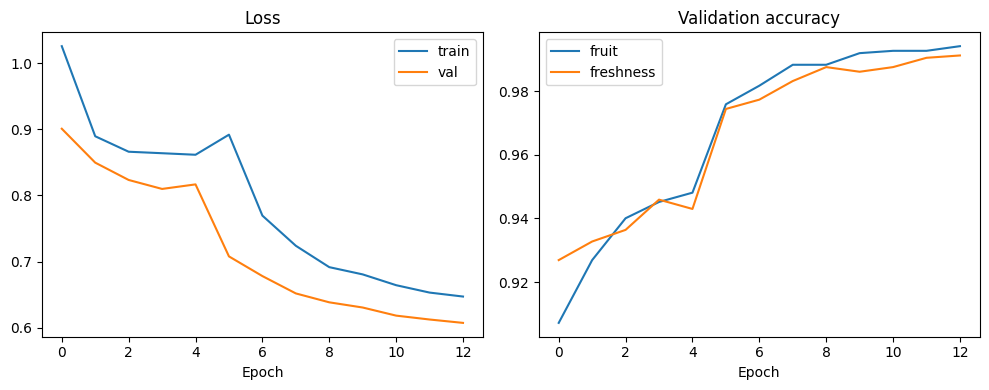

In [10]:
#Learning curves
# Create a figure 10 x 4 inches
plt.figure(figsize=(10, 4))
# Left plot: loss
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="train"); plt.plot(history["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
# Right plot: validation accuracy of both heads
plt.subplot(1, 2, 2)
plt.plot(history["val_fruit_acc"], label="fruit"); plt.plot(history["val_fresh_acc"], label="freshness")
plt.title("Validation accuracy"); plt.xlabel("Epoch"); plt.legend()
# Fix spacing and show the figure
plt.tight_layout(); plt.show()

=============== Test set (dataset) ===============
Fruit accuracy: 0.9942
              precision    recall  f1-score   support

       apple       0.99      0.99      0.99       292
      banana       0.99      1.00      1.00       294
       mango       1.00      0.99      0.99       585
      orange       0.99      0.99      0.99       209

    accuracy                           0.99      1380
   macro avg       0.99      0.99      0.99      1380
weighted avg       0.99      0.99      0.99      1380

Freshness accuracy: 0.9928
Freshness F1 (macro): 0.9927

Per-fruit freshness performance:
  apple      accuracy 0.997 | images 292
  banana     accuracy 0.997 | images 294
  mango      accuracy 0.988 | images 585
  orange     accuracy 0.995 | images 209


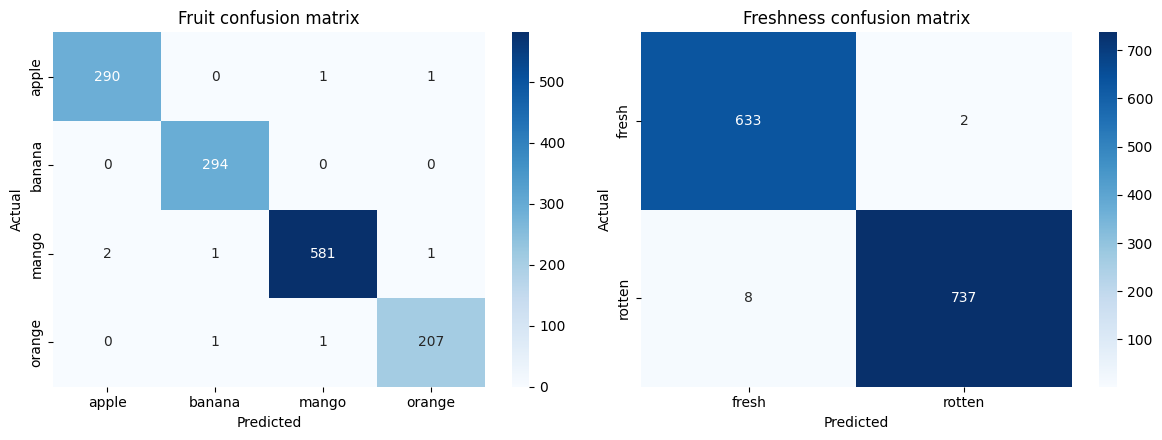


Latency: 5.58 ms per image | FPS: 179.3


In [11]:
#evaluations metrices
# Evaluates the model on any loader and prints/plots all the metrics
def evaluate(loader, title="Test set"):
    # Evaluation mode
    model.eval()
    # Lists for true and predicted labels of the fruit and freshness heads
    fr_true, fr_pred, fs_true, fs_pred = [], [], [], []
    # No gradients needed for evaluation
    with torch.no_grad():
        for images, fruit, fresh in loader:
            # Predict a batch
            out_fruit, out_fresh = model(images.to(device))
            # argmax = predicted class; move to CPU and convert to a Python list
            fr_pred += out_fruit.argmax(1).cpu().tolist()
            fs_pred += out_fresh.argmax(1).cpu().tolist()
            # Save the true labels
            fr_true += fruit.tolist(); fs_true += fresh.tolist()

    print(f"=============== {title} ===============")
    # Fruit accuracy
    print("Fruit accuracy:", round(accuracy_score(fr_true, fr_pred), 4))
    # Precision, recall and F1 for each fruit
    print(classification_report(fr_true, fr_pred, labels=range(len(fruit_list)),
                                target_names=fruit_list, zero_division=0))
    # Freshness accuracy and macro F1 (average F1 of the two classes)
    print("Freshness accuracy:", round(accuracy_score(fs_true, fs_pred), 4))
    print("Freshness F1 (macro):", round(f1_score(fs_true, fs_pred, average="macro"), 4))

    # Freshness accuracy for each fruit separately
    print("\nPer-fruit freshness performance:")
    for i, f in enumerate(fruit_list):
        # Positions of the images whose true fruit is this fruit
        idx = [k for k, t in enumerate(fr_true) if t == i]
        if idx:
            # True and predicted freshness of those images
            t = [fs_true[k] for k in idx]; p = [fs_pred[k] for k in idx]
            print(f"  {f:10s} accuracy {accuracy_score(t, p):.3f} | images {len(idx)}")

    # Two confusion matrices side by side
    plt.figure(figsize=(12, 4.5))
    # Left: fruit confusion matrix (rows = actual, columns = predicted)
    plt.subplot(1, 2, 1)
    sns.heatmap(confusion_matrix(fr_true, fr_pred, labels=range(len(fruit_list))), annot=True,
                fmt="d", cmap="Blues", xticklabels=fruit_list, yticklabels=fruit_list)
    plt.title("Fruit confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
    # Right: freshness confusion matrix
    plt.subplot(1, 2, 2)
    sns.heatmap(confusion_matrix(fs_true, fs_pred, labels=[0, 1]), annot=True, fmt="d",
                cmap="Blues", xticklabels=fresh_list, yticklabels=fresh_list)
    plt.title("Freshness confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.tight_layout(); plt.show()

# Run the evaluation on the test set
evaluate(test_loader, "Test set (dataset)")

# A random fake image (1 image, 3 channels, 224 x 224) used only to time the model
dummy = torch.randn(1, 3, 224, 224).to(device)
with torch.no_grad():
    # Warm-up runs so the first slow runs are not counted
    for _ in range(10): model(dummy)
    # On GPU, wait until all work has finished before starting the timer
    if device.type == "cuda": torch.cuda.synchronize()
    start = time.time()
    # Time 100 single-image predictions
    for _ in range(100): model(dummy)
    if device.type == "cuda": torch.cuda.synchronize()
    total = time.time() - start
# Latency = time per image in ms; FPS = images per second
print(f"\nLatency: {total / 100 * 1000:.2f} ms per image | FPS: {100 / total:.1f}")


In [12]:
# List everything inside the main project folder in Drive; folders are marked "(folder)"
for d in sorted(Path("/content/drive/MyDrive/fresh_vs_rotten_fruit").iterdir()):
    print(d.name, "(folder)" if d.is_dir() else "")

Copy of fresh_vs_rotten_fruit_new.ipynb 
fresh_vs_rotten_dataset.zip 
fresh_vs_rotten_fruit_new.ipynb 
fresh_vs_rotten_my_dataset (folder)
fresh_vs_rotten_my_test_dataset (folder)
old_code(not to be used) (folder)


fresh_apple     photos: 5
fresh_banana    photos: 5
fresh_mango     photos: 5
fresh_orange    photos: 5
rotten_apple    photos: 5
rotten_banana   photos: 5
rotten_mango    photos: 5
rotten_orange   photos: 5
=============== Special test folder (never trained on) ===============
Fruit accuracy: 0.95
              precision    recall  f1-score   support

       apple       0.91      1.00      0.95        10
      banana       1.00      1.00      1.00        10
       mango       1.00      0.90      0.95        10
      orange       0.90      0.90      0.90        10

    accuracy                           0.95        40
   macro avg       0.95      0.95      0.95        40
weighted avg       0.95      0.95      0.95        40

Freshness accuracy: 0.975
Freshness F1 (macro): 0.975

Per-fruit freshness performance:
  apple      accuracy 1.000 | images 10
  banana     accuracy 0.900 | images 10
  mango      accuracy 1.000 | images 10
  orange     accuracy 1.000 | images 10


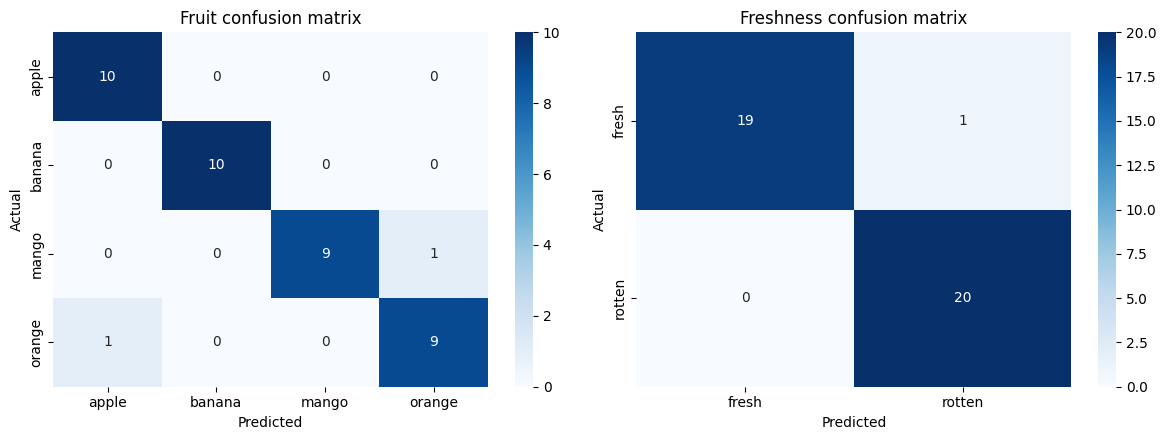

In [13]:
#testing with a manual test set.
# Folder with our own photos that were never used for training
SPECIAL_TEST = Path("/content/drive/MyDrive/fresh_vs_rotten_fruit/fresh_vs_rotten_my_test_dataset")

# Copy only the non-empty class folders to a temporary place
# Temporary folder in Colab
TMP = Path("/content/special_test")
# Delete an old copy first
if TMP.exists():
    shutil.rmtree(TMP)
# Go through the class folders of the test set
for cls_dir in sorted(SPECIAL_TEST.iterdir()):
    # Skip anything that is not a folder
    if not cls_dir.is_dir():
        continue
    # Image files in this class folder
    files = [f for f in cls_dir.glob("*") if f.suffix.lower() in exts]
    print(f"{cls_dir.name:15s} photos: {len(files)}")
    # Copy only if the folder has photos (an empty folder would crash ImageFolder)
    if files:
        (TMP / cls_dir.name).mkdir(parents=True, exist_ok=True)
        for f in files:
            shutil.copy(f, TMP / cls_dir.name / f.name)

# Build a dataset from the copied photos and evaluate the model on it
special_data = FruitData(TMP, eval_tf)
# batch_size=32; no shuffling is needed for evaluation
evaluate(DataLoader(special_data, batch_size=32), "Special test folder (never trained on)")

In [14]:
#saving the model with the manual test set.
# Save only the learned weights (state dict) of the model
torch.save(model.state_dict(), "/content/fruit_model.pth")
# Save the class names, so the app knows what each output number means
with open("/content/labels.json", "w") as f:
    json.dump({"fruits": fruit_list, "fresh": fresh_list}, f)

# Shell command: back up both files to Google Drive, because /content is erased when Colab resets
!cp /content/fruit_model.pth /content/labels.json /content/drive/MyDrive/
print("Model saved!")

Model saved!


In [15]:
#copying the files again
# Shell command: copy the saved files from Drive back to /content (after a Colab reset)
!cp /content/drive/MyDrive/fruit_model.pth /content/drive/MyDrive/labels.json /content/
# List the two files with their sizes to confirm the copy worked
!ls -lh /content/fruit_model.pth /content/labels.json

-rw-r--r-- 1 root root 8.8M Nov 15 10:38 /content/fruit_model.pth
-rw-r--r-- 1 root root   80 Nov 15 10:38 /content/labels.json


In [16]:
%%writefile /content/app.py
#code to put whole into streamlit, to give it a real application like look.
# Everything in this cell is written to the file /content/app.py (it is not run here)
import json, time
import streamlit as st
import torch, torch.nn as nn
from torchvision import models, transforms
# PIL tools: open images, fix rotation, draw on images, fonts
from PIL import Image, ImageOps, ImageDraw, ImageFont

# The live-video package is optional: if it is missing the rest of the app still works
try:
    import av
    from streamlit_webrtc import webrtc_streamer, VideoProcessorBase, RTCConfiguration
    WEBRTC_OK = True
except ImportError:
    WEBRTC_OK = False

# Browser tab title and a centred page layout
st.set_page_config(page_title="Fresh vs Rotten", layout="centered")

# Inject the CSS (colours, card, fonts); unsafe_allow_html=True lets Streamlit render raw HTML/CSS
st.markdown("""
<style>
    ::selection { text-align: center; background: #10b981; color: #030A30; }

    .stApp {
        background-color: #090B1F;
    }
    /* Center everything inside the main app container */
    .block-container {
        padding-top: 3rem;
        max-width: 700px;
        background: linear-gradient( #1F090B 100%);
        border-radius: 16px;
        box-shadow: 0 10px 25px rgba(0, 0, 0, 0.05);
        text-align: center;
        display: flex;
        flex-direction: column;
        align-items: center;
    }

    .block-container > div {
        width: 100%;
    }

    /* Vibrant Title */
    .title {
        font-size: 2.2rem;
        font-weight: 800;
        background: linear-gradient(90deg, #C2DFED, #A5AFE4);
        -webkit-background-clip: text;
        -webkit-text-fill-color: transparent;
        text-align: center;
        margin-bottom: 0.2rem;
    }

    /* Clean Subtitle */
    .subtitle {
        color: #EBEEF9;
        font-size: 1.1rem;
        text-align: center;
        margin-bottom: 2rem;
        font-weight: 500;
    }

    /* Centered Result Cards */
    .card {
        padding: 1.5rem;
        border-radius: 16px;
        margin: 1.2rem auto;
        border-left: 8px solid;
        box-shadow: 0 4px 12px rgba(0,0,0,0.05);
        width: 90%;
        text-align: center;
    }

    /* Fresh State */
    .fresh {
        background: #ecfdf5;
        border-color: #10b981;
        color: #065f46;
    }

    /* Rotten State */
    .rotten {
        background: #fef2f2;
        border-color: #ef4444;
        color: #991b1b;
    }

    .row { font-size: 1.3rem; margin: 0.4rem 0; text-align: center; }
    .label { font-weight: 500; opacity: 0.85; }
    .value { font-weight: 700; }

    /* Center file uploader & images */
    .stFileUploader {
        max-width: 400px;
        margin: 0 auto;
    }

    div.stImage img {
        display: block;
        margin-left: auto;
        margin-right: auto;
        border-radius: 12px;
    }
</style>
""", unsafe_allow_html=True)
# Page heading and subtitles, styled by the .title and .subtitle classes above
st.markdown('<div class="title">Fresh vs Rotten Fruit</div>', unsafe_allow_html=True)
st.markdown('<div class="subtitle">Check the freshness of your fruits</div>', unsafe_allow_html=True)
st.markdown('<div class="subtitle">Apple | Banana | Orange | Mango</div>', unsafe_allow_html=True)


# Same network structure as in training; it must match exactly or the saved weights will not load
class FruitNet(nn.Module):
    def __init__(self, n_fruit, n_fresh, pretrained=True):
        super().__init__()
        weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
        self.features = models.mobilenet_v2(weights=weights).features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(0.3)
        self.fruit_head = nn.Linear(1280, n_fruit)
        self.fresh_head = nn.Linear(1280, n_fresh)
    def forward(self, x):
        x = self.drop(self.pool(self.features(x)).flatten(1))
        return self.fruit_head(x), self.fresh_head(x)

# Cache the model so it is loaded only once, not on every click
@st.cache_resource
def load_model():
    # Read the class names; the path is an absolute Colab path (on a server such as Streamlit Cloud it must point to the file next to app.py)
    labels = json.load(open("/content/labels.json"))
    # Build the empty model; pretrained=False because our own saved weights are loaded next
    model = FruitNet(len(labels["fruits"]), len(labels["fresh"]), pretrained=False)
    # Load our trained weights onto the CPU
    model.load_state_dict(torch.load("/content/fruit_model.pth", map_location="cpu"))
    # Evaluation mode (dropout off)
    model.eval()
    return model, labels["fruits"], labels["fresh"]

# Load the model and labels when the app starts
model, fruits, fresh_names = load_model()

# Same preprocessing as in evaluation
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Runs the model on one image and returns the fruit, its confidence, the status, its confidence and the time taken
def predict(image):
    # Crop the centre square to 224 x 224 instead of squashing the image
    image = ImageOps.fit(image, (224, 224))
    # Preprocess and add a batch dimension (1, 3, 224, 224)
    x = transform(image).unsqueeze(0)
    start = time.time()
    with torch.no_grad():
        out_fruit, out_fresh = model(x)
        # Softmax turns the scores into probabilities for each head
        p_fruit = torch.softmax(out_fruit, 1)[0]
        p_fresh = torch.softmax(out_fresh, 1)[0]
    # Time taken in milliseconds
    ms = (time.time() - start) * 1000
    # Highest probability (confidence) and its class index for each head
    fc, fi = p_fruit.max(0)
    sc, si = p_fresh.max(0)
    return fruits[fi.item()], fc.item(), fresh_names[si.item()], sc.item(), ms

# Predicts and displays the result on the page
def show_result(image):
    fruit, fc, status, sc, ms = predict(image)
    # Result card; the CSS class is "fresh" or "rotten", so the card is green or red
    st.markdown(f"""
    <div class="card {status}">
        <div class="row"><span class="label">Fruit : </span><span class="value">{fruit.title()}</span></div>
        <div class="row"><span class="label">Status : </span><span class="value">{status.title()}</span></div>
    </div>
    """, unsafe_allow_html=True)
    # Confidence text and progress bar for the fruit, then for the status
    st.markdown(f"**Fruit confidence:** {fc * 100:.1f}%")
    st.progress(fc)
    st.markdown(f"**Status confidence:** {sc * 100:.1f}%")
    st.progress(sc)
    # Warn if the less confident of the two is below 60%
    if min(fc, sc) < 0.60:
        st.warning("Low confidence. Place one fruit in the centre with good lighting and retry.")
    # Show the input image and the inference time
    st.image(image, caption="Input image", width=350)
    st.caption(f"Inference time: {ms:.1f} ms")

# Opens an uploaded or camera photo, fixes phone rotation (EXIF) and converts it to RGB
def load_image(file):
    return ImageOps.exif_transpose(Image.open(file)).convert("RGB")

# Live-video code; it is defined here, but no Live tab is created below
if WEBRTC_OK:
    # Called for every video frame by streamlit-webrtc
    class FruitProcessor(VideoProcessorBase):
        def __init__(self):
            # Frame counter and the last prediction (reused between predictions)
            self.count = 0
            self.fruit, self.status, self.fc, self.sc = "", "", 0.0, 0.0

        # Processes one frame and returns the frame with the result drawn on it
        def recv(self, frame):
            img = frame.to_image().convert("RGB")
            self.count += 1
            # Predict only on every 3rd frame to keep the video smooth
            if self.count % 3 == 1:
                self.fruit, self.fc, self.status, self.sc, _ = predict(img)
            # Green for fresh, red for rotten
            colour = (16, 185, 129) if self.status == "fresh" else (239, 68, 68)
            # Text shown on the video
            text = f"{self.fruit.title()} {self.fc*100:.0f}% | {self.status.title()} {self.sc*100:.0f}%"
            # Grey "Not sure" when the confidence is low
            if min(self.fc, self.sc) < 0.60:
                colour, text = (120, 120, 120), "Not sure"
            draw = ImageDraw.Draw(img)
            w, h = img.size
            # Font size scales with the frame width; older Pillow versions do not accept size=, so fall back
            try:
                font = ImageFont.load_default(size=max(18, w // 24))
            except TypeError:
                font = ImageFont.load_default()
            # Coloured border around the frame, then a coloured bar at the top with the text
            draw.rectangle([0, 0, w - 1, h - 1], outline=colour, width=6)
            draw.rectangle([0, 0, w, max(40, w // 12)], fill=colour)
            draw.text((12, 6), text, fill=(255, 255, 255), font=font)
            return av.VideoFrame.from_image(img)

# Two tabs: Upload and Camera
tab1, tab2 = st.tabs(["Upload", "Camera"])

# Upload tab: choose a JPG or PNG file, then show the result
with tab1:
    file = st.file_uploader("Upload a fruit photo", type=["jpg", "jpeg", "png"])
    if file is not None:
        show_result(load_image(file))

# Camera tab: take a photo with the device camera, then show the result
with tab2:
    photo = st.camera_input("Take a photo of the fruit")
    if photo is not None:
        show_result(load_image(photo))

Writing /content/app.py


In [17]:
# Stop any old Streamlit server so the port is free
!pkill -f "[s]treamlit"
# Stop any old tunnel
!pkill -f "[c]loudflared"

#generating streamlit link
# subprocess starts background programs
import subprocess, time, re, os

# Install Streamlit and the live-video package quietly
!pip install -q streamlit streamlit-webrtc
# Download the Cloudflare tunnel program only if it is not already here
if not os.path.exists("cloudflared"):
    !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
    # Make the downloaded file executable
    !chmod +x cloudflared

time.sleep(2)
# Start the Streamlit app in the background on port 8501 without opening a browser
subprocess.Popen(["streamlit", "run", "/content/app.py",
                  "--server.port", "8501", "--server.headless", "true"])
# Give Streamlit a few seconds to start
time.sleep(5)

# Start the tunnel that gives the local app a public https link; its messages go to stderr
proc = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                        stderr=subprocess.PIPE, text=True)
# Read the tunnel's messages until the public link appears
for line in proc.stderr:
    # Look for a link like https://xxxx.trycloudflare.com
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", line)
    if m:
        print("Open your app here:", m.group(0))
        break


Open your app here: https://boot-moisture-paper-exotic.trycloudflare.com
